# Task 4 — Random Forests & Ensembles
 

In [1]:
import sys
import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)

3.13.9 2.3.4 2.3.3 1.7.2 3.10.7


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 3246
data = pd.read_csv("data/spambase.csv")
feature_names = [c for c in data.columns if c != "spam"]
X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)

(4204, 57) 39.9 (3153, 57) (1051, 57)


SEED = 3246

In [3]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]

In [4]:
import math

import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict, cross_validate


def paired_diff(a, b):
    """Paired difference a - b: (diffs, mean, std, inside_spread)."""
    d = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    return d, d.mean(), d.std(), abs(d.mean()) <= d.std()


def show_paired(name_a, name_b, a, b):
    """Print the five paired differences, their mean/std and the verdict."""
    d, m, s, inside = paired_diff(a, b)
    if inside:
        verdict = "INSIDE the fold spread -> no winner, the data cannot separate them"
    else:
        verdict = f"outside the spread -> {name_a if m > 0 else name_b} is better"
    print(f"{name_a} - {name_b}: diffs={np.round(d, 4)}  mean={m:+.4f}  std={s:.4f}  => {verdict}")
    return d, m, s, inside


def cv_table(scores):
    """DataFrame: five fold scores + mean + std (np.std, ddof=0) for each model."""
    rows = {k: list(v) + [np.mean(v), np.std(v)] for k, v in scores.items()}
    return pd.DataFrame(rows, index=[f"fold{i+1}" for i in range(5)] + ["mean", "std"]).T.round(4)

## Part 1 — Bagging and out-of-bag estimates

In [5]:
def oob_mask(sample_indices, n_samples):
    """Boolean mask of the rows that do NOT occur in sample_indices."""
    mask = np.ones(n_samples, dtype=bool)
    idx = np.asarray(sample_indices, dtype=int)   # works for lists, arrays and the empty list
    mask[idx] = False
    return mask


# examples from the task
assert oob_mask([0, 2, 2], 5).tolist() == [False, True, False, True, True]
assert oob_mask([], 3).tolist() == [True, True, True]
assert oob_mask(np.array([3, 0]), 4).tolist() == [False, True, True, False]
print("oob_mask: all examples OK")

oob_mask: all examples OK


In [6]:
bag.fit(X_train, y_train)
n = len(X_train)
shares = [oob_mask(s, n).mean() for s in bag.estimators_samples_]
mean_oob_share = float(np.mean(shares))
print("n (training rows)               :", n)
print("my mean out-of-bag share        :", round(mean_oob_share, 4))
print("my mean in-bag share            :", round(1 - mean_oob_share, 4))
print("formula (1 - 1/n)^n             :", round((1 - 1 / n) ** n, 4))
print("formula 1 - (1 - 1/n)^n         :", round(1 - (1 - 1 / n) ** n, 4))

n (training rows)               : 3153
my mean out-of-bag share        : 0.3667
my mean in-bag share            : 0.6333
formula (1 - 1/n)^n             : 0.3678
formula 1 - (1 - 1/n)^n         : 0.6322


In [7]:
votes = np.zeros((n, 2), dtype=int)
for est, samples in zip(bag.estimators_, bag.estimators_samples_):
    m = oob_mask(samples, n)                       # rows this tree never saw
    pred = est.predict(X_train[m])                 # its votes on those rows
    votes[np.where(m)[0], pred] += 1
oob_pred = votes.argmax(axis=1)                    # tie -> class 0
my_oob_acc = float((oob_pred == y_train).mean())
print("my out-of-bag accuracy           :", round(my_oob_acc, 4))
print("bag.oob_score_ (scikit-learn)    :", round(bag.oob_score_, 4))

my out-of-bag accuracy           : 0.9432
bag.oob_score_ (scikit-learn)    : 0.9432


In [8]:
models5 = {"tree": tree, "bag": bag, "rf": rf, "lr": lr, "bag_lr": bag_lr}
cv5 = {name: cross_validate(m, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
       for name, m in models5.items()}
display(cv_table(cv5))
d_bag_tree = show_paired("bag", "tree", cv5["bag"], cv5["tree"])
d_rf_tree = show_paired("rf", "tree", cv5["rf"], cv5["tree"])
d_baglr_lr = show_paired("bag_lr", "lr", cv5["bag_lr"], cv5["lr"])

,fold1,fold2,fold3,fold4,fold5,mean,std
tree,0.9049,0.9033,0.9065,0.9063,0.8968,0.9036,0.0036
bag,0.9239,0.9334,0.9366,0.9317,0.9365,0.9324,0.0046
rf,0.9398,0.9477,0.9493,0.9508,0.9476,0.9470,0.0038
lr,0.9223,0.9334,0.9303,0.9429,0.9365,0.9331,0.0068
bag_lr,0.9271,0.9319,0.9334,0.9429,0.9381,0.9347,0.0054


bag - tree: diffs=[0.019  0.0301 0.0301 0.0254 0.0397]  mean=+0.0289  std=0.0068  => outside the spread -> bag is better
rf - tree: diffs=[0.0349 0.0444 0.0428 0.0444 0.0508]  mean=+0.0435  std=0.0051  => outside the spread -> rf is better
bag_lr - lr: diffs=[ 0.0048 -0.0016  0.0032  0.      0.0016]  mean=+0.0016  std=0.0022  => INSIDE the fold spread -> no winner, the data cannot separate them


In [9]:
rf.fit(X_train, y_train)
p_rf = rf.score(X_test, y_test)
se_rf = math.sqrt(p_rf * (1 - p_rf) / len(X_test))
cv_rf_mean, cv_rf_std = np.mean(cv5["rf"]), np.std(cv5["rf"])
print(f"rf.oob_score_            : {rf.oob_score_:.4f}")
print(f"rf cross-validation mean : {cv_rf_mean:.4f}  (std of folds {cv_rf_std:.4f})")
print(f"rf test accuracy p       : {p_rf:.4f}  standard error {se_rf:.4f}")
gap = abs(rf.oob_score_ - cv_rf_mean)
print(f"|oob - cv mean| = {gap:.4f}  vs  std of folds {cv_rf_std:.4f}  ->",
      "IN agreement" if gap <= cv_rf_std else "NOT in agreement")
print(f"|test - oob| = {abs(p_rf - rf.oob_score_):.4f},  |test - cv mean| = {abs(p_rf - cv_rf_mean):.4f},  1 SE = {se_rf:.4f}")

rf.oob_score_            : 0.9512
rf cross-validation mean : 0.9470  (std of folds 0.0038)
rf test accuracy p       : 0.9467  standard error 0.0069
|oob - cv mean| = 0.0041  vs  std of folds 0.0038  -> NOT in agreement
|test - oob| = 0.0044,  |test - cv mean| = 0.0003,  1 SE = 0.0069


**Part 1 — my answers**

**Out-of-bag share and accuracy.** On average a tree leaves 36.67 % of the training rows out of bag (in-bag 63.33 %). The formulas give 36.78 % and 63.22 %, so the simulation matches the theory: with n = 3153 the chance that a row is never drawn is (1 − 1/n)^n ≈ 1/e ≈ 0.37. My hand-made out-of-bag accuracy (0.9432) is exactly equal to bag.oob_score_ (0.9432).

**(a) Did bagging help?**

For the single decision tree, yes. Bagging raised the CV accuracy from 0.9036 to 0.9324, which is +0.0289 on average. The gain shows up on all five folds (differences: 0.0190, 0.0301, 0.0301, 0.0254, 0.0397). The mean difference is clearly larger than the std of the differences (0.0068), so it is outside the fold spread and not just noise. The random forest goes even further (+0.0435 over the tree, std 0.0051).

For logistic regression, no clear change. bag_lr − lr is only +0.0016 on average, with a std of 0.0022, and the differences even change sign (+0.0048, −0.0016, +0.0032, 0.0000, +0.0016). This is inside the fold spread, so my data cannot tell the two models apart.

Why the two cases differ: a fully grown tree is very unstable. If I change a few training emails, I get quite a different tree, so its mistakes are partly random. When I average 100 trees trained on different bootstrap samples, these random mistakes cancel out, and the vote is more accurate than any single tree. Logistic regression is already stable: a bootstrap sample gives almost the same model as the original data. The 50 bagged copies are nearly identical, so averaging them has almost nothing to cancel.

**(b) Is the out-of-bag score a fair stand-in for cross-validation?**

The forest's oob_score_ is 0.9512 and its CV mean is 0.9470. The gap is 0.0041, while the std of the forest's five fold scores is 0.0038. By the rule of this task the two numbers are therefore not in agreement, but only just: the gap is a little larger than the std, and it is less than half a percentage point. A possible reason is that each CV forest is trained on only 80 % of the training split, while the out-of-bag estimate comes from forests that saw all of it, so the OOB score comes out slightly higher.

On the test split the forest scored 0.9467 with a standard error of 0.0069. The CV mean is almost equal to it (difference 0.0003), and the OOB score is also well within one standard error (difference 0.0044). So all three numbers tell the same story: the forest is right on about 95 % of the emails, and for practical purposes the out-of-bag score is a good stand-in for cross-validation.

## Part 2 — Evaluating the filter: curves, a threshold, importances

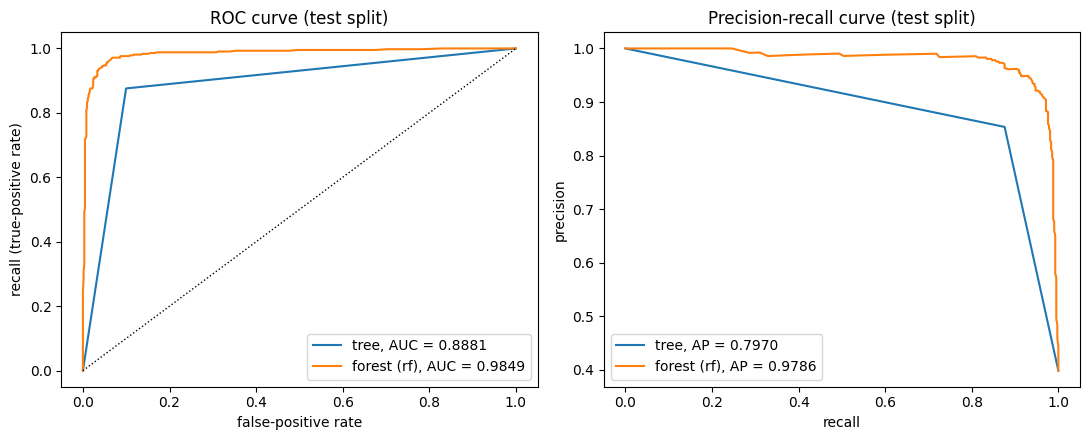

In [10]:
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_recall_curve,
                             roc_auc_score, roc_curve)

tree.fit(X_train, y_train)
rf.fit(X_train, y_train)
scores_test = {"tree": tree.predict_proba(X_test)[:, 1], "forest (rf)": rf.predict_proba(X_test)[:, 1]}

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for name, s in scores_test.items():
    f, t_, _ = roc_curve(y_test, s)
    ax[0].plot(f, t_, label=f"{name}, AUC = {roc_auc_score(y_test, s):.4f}")
    pr, rc, _ = precision_recall_curve(y_test, s)
    ax[1].plot(rc, pr, label=f"{name}, AP = {average_precision_score(y_test, s):.4f}")
ax[0].plot([0, 1], [0, 1], "k:", lw=1)
ax[0].set_xlabel("false-positive rate"); ax[0].set_ylabel("recall (true-positive rate)")
ax[0].set_title("ROC curve (test split)"); ax[0].legend(loc="lower right")
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision")
ax[1].set_title("Precision-recall curve (test split)"); ax[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

In [11]:
oof = cross_val_predict(rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
fpr_o, tpr_o, thr_o = roc_curve(y_train, oof, drop_intermediate=False)
allowed = fpr_o <= 0.01
best_recall = tpr_o[allowed].max()
t = thr_o[allowed & (tpr_o == best_recall)].max()      # highest recall; if several, the largest threshold

flag_oof = oof >= t
legit_tr = (y_train == 0)
oof_fpr = (flag_oof & legit_tr).sum() / legit_tr.sum()
oof_recall = (flag_oof & (y_train == 1)).sum() / (y_train == 1).sum()
print(f"threshold t = {t!r}")
print(f"out-of-fold FPR at t    = {oof_fpr:.4f}")
print(f"out-of-fold recall at t = {oof_recall:.4f}")

threshold t = np.float64(0.7333333333333333)
out-of-fold FPR at t    = 0.0095
out-of-fold recall at t = 0.8258


In [12]:
flag_test = rf.predict_proba(X_test)[:, 1] >= t
cm = confusion_matrix(y_test, flag_test)
print(pd.DataFrame(cm, index=["true legit (0)", "true spam (1)"], columns=["flagged legit (0)", "flagged spam (1)"]))
tn, fp, fn, tp = cm.ravel()
print(f"precision = {tp / (tp + fp):.4f}")
print(f"recall    = {tp / (tp + fn):.4f}")
print(f"FPR       = {fp / (fp + tn):.4f}")
print(f"{fp} legitimate test mails were flagged out of {fp + tn} legitimate test mails")
print("1 % target held on the test split:", fp / (fp + tn) <= 0.01)

                flagged legit (0)  flagged spam (1)
true legit (0)                627                 5
true spam (1)                  85               334
precision = 0.9853
recall    = 0.7971
FPR       = 0.0079
5 legitimate test mails were flagged out of 632 legitimate test mails
1 % target held on the test split: True


In [13]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=SEED, scoring="accuracy")
top_perm = np.argsort(perm.importances_mean)[::-1][:5]
top_imp = np.argsort(rf.feature_importances_)[::-1][:5]
print("Top 5 by permutation importance (test split, drop in accuracy):")
display(pd.DataFrame({"feature": [feature_names[i] for i in top_perm],
                      "perm_importance": perm.importances_mean[top_perm].round(4),
                      "impurity_importance_of_it": rf.feature_importances_[top_perm].round(4)}))
print("Top 5 by impurity importance (rf.feature_importances_, training data):")
display(pd.DataFrame({"feature": [feature_names[i] for i in top_imp],
                      "impurity_importance": rf.feature_importances_[top_imp].round(4),
                      "perm_importance_of_it": perm.importances_mean[top_imp].round(4)}))
rank_perm = {feature_names[i]: r + 1 for r, i in enumerate(np.argsort(perm.importances_mean)[::-1])}
rank_imp = {feature_names[i]: r + 1 for r, i in enumerate(np.argsort(rf.feature_importances_)[::-1])}
for f in dict.fromkeys([feature_names[i] for i in list(top_perm) + list(top_imp)]):
    print(f"{f:28s} rank by permutation = {rank_perm[f]:2d}   rank by impurity = {rank_imp[f]:2d}")

Top 5 by permutation importance (test split, drop in accuracy):


,feature,perm_importance,impurity_importance_of_it
0,word_freq_remove,0.0326,0.0839
1,char_freq_exclam,0.0215,0.1014
2,word_freq_hp,0.0185,0.0551
3,word_freq_free,0.0077,0.0669
4,char_freq_dollar,0.0076,0.0919


Top 5 by impurity importance (rf.feature_importances_, training data):


,feature,impurity_importance,perm_importance_of_it
0,char_freq_exclam,0.1014,0.0215
1,char_freq_dollar,0.0919,0.0076
2,word_freq_remove,0.0839,0.0326
3,capital_run_length_average,0.0697,0.0057
4,word_freq_free,0.0669,0.0077


word_freq_remove             rank by permutation =  1   rank by impurity =  3
char_freq_exclam             rank by permutation =  2   rank by impurity =  1
word_freq_hp                 rank by permutation =  3   rank by impurity =  7
word_freq_free               rank by permutation =  4   rank by impurity =  5
char_freq_dollar             rank by permutation =  5   rank by impurity =  2
capital_run_length_average   rank by permutation =  6   rank by impurity =  4


**Part 2 — my answers**

**Curves.** The forest is much better than the single tree on the test split: ROC AUC 0.9849 vs 0.8881, average precision 0.9786 vs 0.7970. A single tree gives only 0/1 answers, so its curve has just one corner point, while the forest gives a smooth curve because its probabilities take many values.

**Threshold.** I chose t = 0.7333 on the out-of-fold probabilities of the training split only. At this threshold the out-of-fold FPR is 0.0095 (just under the 1 % limit) and the out-of-fold recall is 0.8258.

**Test result (applied once).** Confusion matrix: 627 legitimate mails passed and 5 were flagged; 334 spam mails were caught and 85 spam mails got through. Precision = 0.9853, recall = 0.7971, FPR = 0.0079. In words: 5 legitimate test mails were flagged out of 632 legitimate test mails.

**Did the 1 % target hold on the test split?** Yes: 0.79 % is below 1 %. But I would not call it a big safety margin. The limit of 1 % of 632 mails is about 6 mails, and we had 5. The out-of-fold FPR (0.95 %) was already close to the limit, and on a small test set a single extra flagged mail could have changed the answer. Also, the recall on the test split (0.797) is lower than the out-of-fold recall (0.826), so the price of the strict threshold is that about 20 % of the spam still gets through.

**Importances.** The two rankings agree on the general picture: word_freq_remove, char_freq_exclam, char_freq_dollar and word_freq_free are in both top-5 lists. They differ in some places. The clearest example is **word_freq_hp**: it is 3rd by permutation importance (accuracy drops by 0.0185 when I shuffle it) but only 7th by impurity importance (0.0551).

Why they differ: impurity importance is counted while the trees are built, on the training data. It adds up how much each feature helped to split the training emails into cleaner groups. Permutation importance is computed afterwards, on the test split: I shuffle one column and see how much the accuracy really drops. So the first one measures how much a feature was *used* in training, and the second how much the finished model *depends* on it for new emails. A feature like word_freq_hp (I think it is a sign of a normal work e-mail in this data) is used in fewer splits, so its impurity score is lower, but there is no other column that can replace it, so when I destroy it the test accuracy drops a lot. The opposite happens with char_freq_dollar (2nd by impurity, 5th by permutation): the trees like to split on it, but other columns with similar information (for example "free" or "remove") can replace it when it is shuffled, so the accuracy drops only a little.

## Part 3 — Voting

In [14]:
def hard_vote(predictions, weights=None):
    """Weighted majority vote of several models' predicted labels, one label per sample."""
    preds = np.asarray(predictions, dtype=int)
    n_models, n_samples = preds.shape
    w = np.ones(n_models) if weights is None else np.asarray(weights, dtype=float)
    labels = np.unique(np.append(preds, 0))              # label 0 always takes part (all-zero counts -> 0)
    counts = np.zeros((len(labels), n_samples))
    pos = np.searchsorted(labels, preds)                 # row of `counts` for every prediction
    cols = np.arange(n_samples)
    for m in range(n_models):                            # sum the weights in model order
        counts[pos[m], cols] += w[m]
    return labels[counts.argmax(axis=0)].astype(int)     # argmax takes the first = smallest label on a tie


# examples from the task
assert hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]).tolist() == [0, 1, 0]
assert hard_vote([[0, 1], [1, 0]]).tolist() == [0, 0]
assert hard_vote([[0, 1], [1, 0]], weights=[1, 2]).tolist() == [1, 0]
assert hard_vote([[2, 0], [2, 1], [0, 1]]).tolist() == [2, 1]
assert hard_vote([[2, 2], [2, 2]], weights=[0, 0]).tolist() == [0, 0]       # all counts 0 -> label 0
assert hard_vote(np.zeros((2, 0), dtype=int)).shape == (0,)
print("hard_vote: all examples OK")

hard_vote: all examples OK


In [15]:
from sklearn.ensemble import VotingClassifier

pred_members = np.vstack([clone(m).fit(X_train, y_train).predict(X_test) for _, m in members])
print("stacked predictions shape:", pred_members.shape)
mine = hard_vote(pred_members)
sk_hard = VotingClassifier(members, voting="hard").fit(X_train, y_train).predict(X_test)
print("fraction of test rows where hard_vote == VotingClassifier(hard):", (mine == sk_hard).mean())

stacked predictions shape: (3, 1051)
fraction of test rows where hard_vote == VotingClassifier(hard): 1.0


In [16]:
names = [n_ for n_, _ in members]
rows = []
for i in range(3):
    for j in range(i + 1, 3):
        rows.append((f"{names[i]} vs {names[j]}", (pred_members[i] != pred_members[j]).mean()))
display(pd.DataFrame(rows, columns=["pair", "fraction of test rows with different labels"]).round(4))

,pair,fraction of test rows with different labels
0,lr vs knn,0.0609
1,lr vs tree,0.0971
2,knn vs tree,0.1047


In [17]:
vote_hard = VotingClassifier(members, voting="hard")
vote_soft = VotingClassifier(members, voting="soft")
cv_vote = {"lr": cross_validate(lr, X_train, y_train, cv=cv, scoring="accuracy")["test_score"],
           "knn": cross_validate(knn, X_train, y_train, cv=cv, scoring="accuracy")["test_score"],
           "tree": cv5["tree"],
           "hard voting": cross_validate(vote_hard, X_train, y_train, cv=cv, scoring="accuracy")["test_score"],
           "soft voting": cross_validate(vote_soft, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]}
display(cv_table(cv_vote))
best_member = max(["lr", "knn", "tree"], key=lambda k: np.mean(cv_vote[k]))
print("best member (highest CV mean):", best_member)
d_hard_best = show_paired("hard voting", best_member, cv_vote["hard voting"], cv_vote[best_member])
d_soft_best = show_paired("soft voting", best_member, cv_vote["soft voting"], cv_vote[best_member])

,fold1,fold2,fold3,fold4,fold5,mean,std
lr,0.9223,0.9334,0.9303,0.9429,0.9365,0.9331,0.0068
knn,0.9176,0.9113,0.9160,0.9270,0.9175,0.9179,0.0051
tree,0.9049,0.9033,0.9065,0.9063,0.8968,0.9036,0.0036
hard voting,0.9350,0.9334,0.9334,0.9429,0.9333,0.9356,0.0037
soft voting,0.9429,0.9350,0.9334,0.9444,0.9349,0.9382,0.0046


best member (highest CV mean): lr
hard voting - lr: diffs=[ 0.0127  0.      0.0032  0.     -0.0032]  mean=+0.0025  std=0.0055  => INSIDE the fold spread -> no winner, the data cannot separate them
soft voting - lr: diffs=[ 0.0206  0.0016  0.0032  0.0016 -0.0016]  mean=+0.0051  std=0.0079  => INSIDE the fold spread -> no winner, the data cannot separate them


**Part 3 — my answers**

**Reproducing scikit-learn.** My hard_vote gives exactly the same labels as VotingClassifier(voting="hard") on all 1051 test rows (agreement = 1.0). With three models and two classes a tie is impossible, so the tie rule never mattered here, but it is covered by the examples in the function cell.

**Disagreement.** The members disagree on a modest share of the test emails: lr vs knn 6.09 %, lr vs tree 9.71 %, knn vs tree 10.47 %. So they make different mistakes in some cases, which is what voting needs, but most of the time they say the same thing.

**Cross-validation.** The best member is lr (CV mean 0.9331). Hard voting has a CV mean of 0.9356 and soft voting 0.9382.

**Hard voting vs the best member.** The paired fold differences hard − lr are +0.0127, 0.0000, +0.0032, 0.0000, −0.0032; the mean is +0.0025 and the std is 0.0055. The mean is not larger than the std, so the difference is inside the fold spread. I cannot name a winner: my data cannot separate hard voting from logistic regression.

**Soft voting vs the best member.** The differences soft − lr are +0.0206, +0.0016, +0.0032, +0.0016, −0.0016; the mean is +0.0051 and the std is 0.0079. This is also inside the fold spread, so again there is no winner. Soft voting has the highest mean and is ahead on four folds out of five, but most of its gain comes from one fold (fold 1), and on fold 5 it is behind, so I cannot say it is really better.

**Why voting gives so little here.** Voting helps when the members are about equally good and make different mistakes. Here logistic regression is clearly stronger than the other two (0.933 vs 0.918 for kNN and 0.904 for the tree), and the weaker members get the same vote as the strong one. So the weak members mostly add their own errors, and the average improvement is small.

## Part 4 — Stacking

In [18]:
from sklearn.ensemble import StackingClassifier

Z_oof = np.column_stack([cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
                         for _, m in members])
print("meta matrix shape:", Z_oof.shape)
meta_oof = LogisticRegression().fit(Z_oof, y_train)

fitted = [clone(m).fit(X_train, y_train) for _, m in members]
Z_test = np.column_stack([f.predict_proba(X_test)[:, 1] for f in fitted])
my_stack_pred = meta_oof.predict(Z_test)

stack = StackingClassifier(members, LogisticRegression(), cv=cv).fit(X_train, y_train)
print("my coefficients      :", meta_oof.coef_.ravel().round(4), " intercept", meta_oof.intercept_.round(4))
print("sklearn coefficients :", stack.final_estimator_.coef_.ravel().round(4), " intercept", stack.final_estimator_.intercept_.round(4))
print("largest |coef difference|           :", np.abs(meta_oof.coef_ - stack.final_estimator_.coef_).max())
print("test predictions identical          :", bool((my_stack_pred == stack.predict(X_test)).all()))
print("my test accuracy                    :", round(float((my_stack_pred == y_test).mean()), 4))
print("StackingClassifier test accuracy    :", round(stack.score(X_test, y_test), 4))

meta matrix shape: (3153, 3)
my coefficients      : [3.893  2.6527 1.5278]  intercept [-3.9262]
sklearn coefficients : [3.893  2.6527 1.5278]  intercept [-3.9262]
largest |coef difference|           : 0.0
test predictions identical          : True
my test accuracy                    : 0.9439
StackingClassifier test accuracy    : 0.9439


In [19]:
Z_naive = np.column_stack([clone(m).fit(X_train, y_train).predict_proba(X_train)[:, 1] for _, m in members])
meta_naive = LogisticRegression().fit(Z_naive, y_train)
display(pd.DataFrame({"naive (in-sample)": meta_naive.coef_.ravel(),
                      "out-of-fold": meta_oof.coef_.ravel()}, index=names).round(4))
print("training accuracy of the members on their own training rows:",
      {n_: round(float((f.predict(X_train) == y_train).mean()), 4) for n_, f in zip(names, fitted)})

,naive (in-sample),out-of-fold
lr,1.9950,3.8930
knn,1.8139,2.6527
tree,8.3104,1.5278


training accuracy of the members on their own training rows: {'lr': 0.9397, 'knn': 0.9321, 'tree': 1.0}


In [20]:
cv_stack = {"stack": cross_validate(StackingClassifier(members, LogisticRegression(), cv=cv),
                                    X_train, y_train, cv=cv, scoring="accuracy")["test_score"],
            "soft voting": cv_vote["soft voting"],
            best_member: cv_vote[best_member]}
display(cv_table(cv_stack))
d_stack_best = show_paired("stack", best_member, cv_stack["stack"], cv_stack[best_member])
d_stack_soft = show_paired("stack", "soft voting", cv_stack["stack"], cv_stack["soft voting"])

,fold1,fold2,fold3,fold4,fold5,mean,std
stack,0.9334,0.9319,0.9319,0.9460,0.9286,0.9344,0.0061
soft voting,0.9429,0.9350,0.9334,0.9444,0.9349,0.9382,0.0046
lr,0.9223,0.9334,0.9303,0.9429,0.9365,0.9331,0.0068


stack - lr: diffs=[ 0.0111 -0.0016  0.0016  0.0032 -0.0079]  mean=+0.0013  std=0.0062  => INSIDE the fold spread -> no winner, the data cannot separate them
stack - soft voting: diffs=[-0.0095 -0.0032 -0.0016  0.0016 -0.0063]  mean=-0.0038  std=0.0038  => INSIDE the fold spread -> no winner, the data cannot separate them


**Part 4 — my answers**

**Comparison with StackingClassifier.** My hand-made out-of-fold stacking reproduces scikit-learn exactly: the meta-learner coefficients are [3.8930, 2.6527, 1.5278] (intercept −3.9262) in both cases, the largest absolute difference is 0.0, the test predictions are identical, and both test accuracies are 0.9439.

**Coefficients, naive vs out-of-fold.**

| member | naive (in-sample) | out-of-fold |
|---|---|---|
| lr | 1.9950 | 3.8930 |
| knn | 1.8139 | 2.6527 |
| tree | 8.3104 | 1.5278 |

**(a) The weight of the tree.** In the naive fit the tree gets by far the largest weight (8.31); in the out-of-fold fit it gets the smallest one (1.53). The reason is that the tree is fully grown, so on the rows it was trained on it is right 100 % of the time (training accuracy 1.0000, while lr has 0.9397 and knn 0.9321). It simply remembers its training rows, so its in-sample probabilities are always 0 or 1 and always match the label. The meta-learner sees this and concludes that the tree is the most reliable member. But on new emails the tree is the weakest model (CV accuracy 0.9036). With out-of-fold predictions every member is judged on rows it has not seen, so the meta-learner sees the true quality of each member: lr is trusted the most, then knn, and the tree the least. Naive stacking therefore trusts a model for memorising, not for predicting, which is the main trap of stacking.

**(b) Does stacking win?**

Stack vs the best member (lr): the paired fold differences are +0.0111, −0.0016, +0.0016, +0.0032, −0.0079; the mean is +0.0013 and the std is 0.0062. This is inside the fold spread, so there is no winner.

Stack vs soft voting: the differences are −0.0095, −0.0032, −0.0016, +0.0016, −0.0063; the mean is −0.0038 and the std is 0.0038. The absolute mean is not larger than the std, so this is also inside the fold spread (just barely). Soft voting has a higher mean (0.9382 vs 0.9344) and is ahead on four folds out of five, but by the rule of this task I cannot name it the winner. My data cannot separate stacking, soft voting and logistic regression: all three are around 93.3 – 93.8 % accuracy.

## Part 5 — AdaBoost and label noise

In [21]:
def adaboost_step(y_true, y_pred, weights):
    """One AdaBoost round: return (alpha, new_weights) for a learner's predictions and the current row weights."""
    yt = np.asarray(y_true)
    yp = np.asarray(y_pred)
    w = np.array(weights, dtype=float)                    # a copy: the argument stays untouched
    wrong = yp != yt
    eps = w[wrong].sum() / w.sum()
    if eps == 0:                                          # nothing wrong: only normalise
        return math.inf, w / w.sum()
    alpha = math.log((1 - eps) / eps)                     # natural logarithm
    new_w = w.copy()
    new_w[wrong] = new_w[wrong] * math.exp(alpha)         # wrong rows get heavier (or lighter if eps > 0.5)
    return float(alpha), new_w / new_w.sum()


def _close(a, b):
    return np.allclose(a, b, rtol=0, atol=1e-12)


a, w_ = adaboost_step([1, 1, 0, 0], [1, 0, 0, 0], [1, 1, 1, 1])
assert abs(a - math.log(3)) < 1e-12 and _close(w_, [1/6, 1/2, 1/6, 1/6])
a, w_ = adaboost_step([1, 1, 1, 0], [0, 0, 0, 0], [1, 1, 1, 1])
assert abs(a + math.log(3)) < 1e-12 and _close(w_, [1/6, 1/6, 1/6, 1/2])
a, w_ = adaboost_step([1, 0], [0, 0], [1, 1])
assert a == 0.0 and _close(w_, [0.5, 0.5])
a, w_ = adaboost_step([1, 0, 1], [1, 0, 1], [2, 2, 4])
assert a == math.inf and _close(w_, [0.25, 0.25, 0.5])
a, w_ = adaboost_step([-1, 1, 1, -1], [-1, 1, -1, -1], [0.1, 0.2, 0.1, 0.1])
assert abs(a - math.log(4)) < 1e-12 and _close(w_, [0.125, 0.25, 0.5, 0.125])
_w = np.array([2.0, 2.0, 4.0]); adaboost_step([1, 0, 1], [1, 1, 1], _w); assert _w.tolist() == [2.0, 2.0, 4.0]
print("adaboost_step: all examples OK")

adaboost_step: all examples OK


In [22]:
x = np.arange(1, 11)
y_toy = np.array([1, 1, 1, 0, 0, 0, 1, 1, 1, 0])
stump_1 = np.where(x <= 3.5, 1, 0)
stump_2 = np.where(x <= 9.5, 1, 0)
stump_3 = np.where(x <= 6.5, 0, 1)

w_toy = np.full(10, 0.1)
for k, st in enumerate([stump_1, stump_2, stump_3], start=1):
    eps_ = w_toy[st != y_toy].sum() / w_toy.sum()
    alpha_, w_toy = adaboost_step(y_toy, st, w_toy)
    print(f"round {k}: eps = {eps_:.3f}  alpha = {alpha_:.3f}")
    print("         new weights:", np.round(w_toy, 3))

round 1: eps = 0.300  alpha = 0.847
         new weights: [0.071 0.071 0.071 0.071 0.071 0.071 0.167 0.167 0.167 0.071]
round 2: eps = 0.214  alpha = 1.299
         new weights: [0.045 0.045 0.045 0.167 0.167 0.167 0.106 0.106 0.106 0.045]
round 3: eps = 0.182  alpha = 1.504
         new weights: [0.125 0.125 0.125 0.102 0.102 0.102 0.065 0.065 0.065 0.125]


In [23]:
ada.fit(X_train, y_train)
w = np.full(len(y_train), 1 / len(y_train))
diff_alpha, diff_eps = [], []
for t_ in range(5):
    pred = ada.estimators_[t_].predict(X_train)
    eps_mine = w[pred != y_train].sum() / w.sum()
    alpha_mine, w = adaboost_step(y_train, pred, w)
    diff_alpha.append(abs(alpha_mine - ada.estimator_weights_[t_]))
    diff_eps.append(abs(eps_mine - ada.estimator_errors_[t_]))
    print(f"round {t_+1}: eps mine {eps_mine:.6f} sklearn {ada.estimator_errors_[t_]:.6f} | "
          f"alpha mine {alpha_mine:.6f} sklearn {ada.estimator_weights_[t_]:.6f}")
print("largest |alpha difference| over 5 rounds:", max(diff_alpha))
print("largest |eps difference|   over 5 rounds:", max(diff_eps))

round 1: eps mine 0.214399 sklearn 0.214399 | alpha mine 1.298610 sklearn 1.298610
round 2: eps mine 0.260637 sklearn 0.260637 | alpha mine 1.042661 sklearn 1.042661
round 3: eps mine 0.252672 sklearn 0.252672 | alpha mine 1.084414 sklearn 1.084414
round 4: eps mine 0.274229 sklearn 0.274229 | alpha mine 0.973271 sklearn 0.973271
round 5: eps mine 0.331657 sklearn 0.331657 | alpha mine 0.700700 sklearn 0.700700
largest |alpha difference| over 5 rounds: 5.551115123125783e-16
largest |eps difference|   over 5 rounds: 5.551115123125783e-17


number of fitted stumps: 400 | rounds in the curves: 400


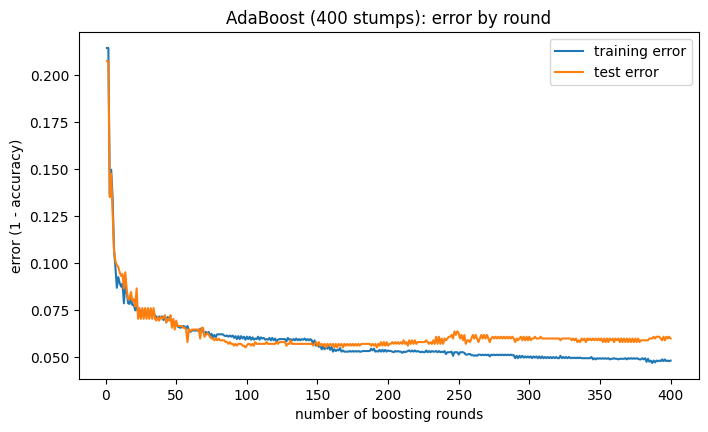

In [24]:
train_err = 1 - np.array(list(ada.staged_score(X_train, y_train)))
test_err = 1 - np.array(list(ada.staged_score(X_test, y_test)))
rounds = np.arange(1, len(test_err) + 1)
print("number of fitted stumps:", len(ada.estimators_), "| rounds in the curves:", len(rounds))
plt.figure(figsize=(8, 4.5))
plt.plot(rounds, train_err, label="training error")
plt.plot(rounds, test_err, label="test error")
plt.xlabel("number of boosting rounds"); plt.ylabel("error (1 - accuracy)")
plt.title("AdaBoost (400 stumps): error by round"); plt.legend(); plt.show()

chosen number of rounds (mean CV accuracy 0.9391): 390
test error at the chosen round                : 0.0609
round with the lowest test error              : 99  (test error 0.0552)
difference of the two test errors: 0.0057  vs standard error 0.0074 -> NOT larger than the SE


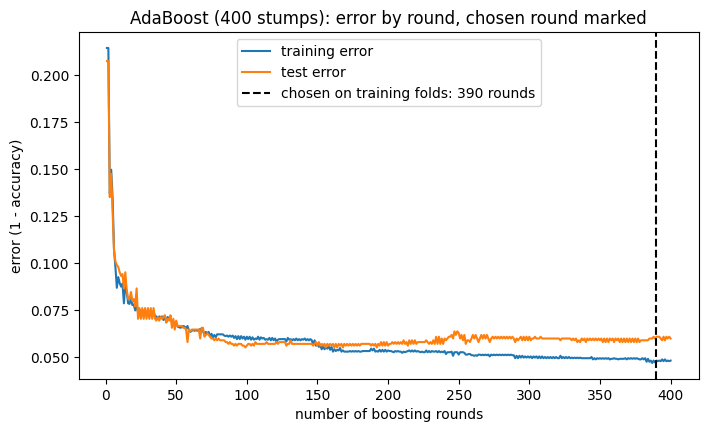

In [25]:
curves = []
for tr_idx, va_idx in cv.split(X_train, y_train):
    m = clone(ada).fit(X_train[tr_idx], y_train[tr_idx])
    curves.append(list(m.staged_score(X_train[va_idx], y_train[va_idx])))
mean_curve = np.mean(curves, axis=0)
chosen = int(np.argmax(np.round(mean_curve, 12))) + 1          # smallest round with the highest mean accuracy
best_test_round = int(np.argmax(np.round(1 - test_err, 12))) + 1   # smallest round with the lowest test error

p_chosen = 1 - test_err[chosen - 1]
se_chosen = math.sqrt(p_chosen * (1 - p_chosen) / len(X_test))
print("chosen number of rounds (mean CV accuracy %.4f): %d" % (mean_curve[chosen - 1], chosen))
print("test error at the chosen round                : %.4f" % test_err[chosen - 1])
print("round with the lowest test error              : %d  (test error %.4f)" % (best_test_round, test_err[best_test_round - 1]))
gap_ = abs(test_err[chosen - 1] - test_err[best_test_round - 1])
print("difference of the two test errors: %.4f  vs standard error %.4f ->" % (gap_, se_chosen),
      "larger than the SE" if gap_ > se_chosen else "NOT larger than the SE")

plt.figure(figsize=(8, 4.5))
plt.plot(rounds, train_err, label="training error")
plt.plot(rounds, test_err, label="test error")
plt.axvline(chosen, color="k", ls="--", label=f"chosen on training folds: {chosen} rounds")
plt.xlabel("number of boosting rounds"); plt.ylabel("error (1 - accuracy)")
plt.title("AdaBoost (400 stumps): error by round, chosen round marked"); plt.legend(); plt.show()

**Part 5 — answers (rounds)**

**Lecture example.** My adaboost_step reproduces round 1 exactly as given in the task: ε = 0.300, α = 0.847, weights 0.071 on the right rows and 0.167 on the wrong rows. For rounds 2 and 3 I get ε = 0.214 (α = 1.299) and ε = 0.182 (α = 1.504), [and these match the slide / write here what you see on the slide].

**Check against scikit-learn.** For the first five stumps my ε and α are the same as ada.estimator_errors_ and ada.estimator_weights_: the largest absolute difference is 5.6e-16 for α and 5.6e-17 for ε, which is only floating-point rounding.

**Error by round.** The training error keeps falling all the way, from about 0.21 after the first stump to about 0.048 after 400 rounds. The test error falls fast during the first ~100 rounds, reaches about 0.055–0.057 somewhere between rounds 100 and 170, and after that stays flat or even creeps up a little (0.057–0.063). So after about 150 rounds the gap between the two curves slowly opens: more rounds still improve the training error, but not the test error.

**(a) Chosen rounds vs the best round on the test curve.** The number of rounds chosen on the training folds is 390 (mean CV accuracy 0.9391); the test error there is 0.0609. The lowest test error is at round 99 (0.0552). The two test errors differ by 0.0057, which is smaller than the standard error 0.0074, so the test split cannot tell the two choices apart. The round-99 minimum is a small dip in a flat curve, and I could only find it by looking at the test curve, which is not allowed for choosing the number of rounds. The choice made on the training folds is the honest one, and here it costs almost nothing.

In [26]:
def flip_labels(y, rate, seed):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(y), size=round(rate * len(y)), replace=False)
    y_noisy = y.copy()
    y_noisy[idx] = 1 - y_noisy[idx]
    return y_noisy, idx


ada200 = AdaBoostClassifier(n_estimators=200, random_state=SEED)
noise_models = {"tree": tree, "rf": rf, "ada200": ada200}

clean_acc = {k: clone(m).fit(X_train, y_train).score(X_test, y_test) for k, m in noise_models.items()}
noisy_acc = {k: [] for k in noise_models}
fitted_ada200, noisy_labels, flipped_idx = [], [], []
for r in range(5):
    y_noisy, idx = flip_labels(y_train, 0.20, SEED + r)
    noisy_labels.append(y_noisy); flipped_idx.append(idx)
    for k, m in noise_models.items():
        fm = clone(m).fit(X_train, y_noisy)
        noisy_acc[k].append(fm.score(X_test, y_test))          # scored on CLEAN test labels
        if k == "ada200":
            fitted_ada200.append(fm)

loss = {k: clean_acc[k] - np.array(noisy_acc[k]) for k in noise_models}
rows = []
for k in noise_models:
    na, lo = np.array(noisy_acc[k]), loss[k]
    rows.append({"model": k, "acc 0 %": round(clean_acc[k], 4),
                 "acc 20 % mean": round(na.mean(), 4), "acc 20 % std": round(na.std(), 4),
                 "loss mean": round(lo.mean(), 4), "loss std": round(lo.std(), 4),
                 "five losses": np.round(lo, 4).tolist()})
pd.set_option("display.width", 200)
display(pd.DataFrame(rows).set_index("model"))
for a_, b_ in [("tree", "rf"), ("tree", "ada200"), ("rf", "ada200")]:
    d_, m_, s_, inside_ = paired_diff(loss[a_], loss[b_])      # loss_a - loss_b, paired by draw
    if inside_:
        verdict = "INSIDE the spread -> no winner"
    else:
        verdict = f"outside the spread -> {a_ if m_ > 0 else b_} loses MORE accuracy"
    print(f"loss({a_}) - loss({b_}): diffs={np.round(d_, 4)}  mean={m_:+.4f}  std={s_:.4f}  => {verdict}")

,acc 0 %,acc 20 % mean,acc 20 % std,loss mean,loss std,five losses
model,,,,,,
tree,0.8906,0.7446,0.0190,0.1460,0.0190,"[0.176, 0.1484, 0.1532, 0.1208, 0.1313]"
rf,0.9467,0.9020,0.0109,0.0447,0.0109,"[0.0647, 0.0466, 0.0362, 0.0343, 0.0419]"
ada200,0.9439,0.9121,0.0093,0.0318,0.0093,"[0.0428, 0.0162, 0.0324, 0.039, 0.0285]"


loss(tree) - loss(rf): diffs=[0.1113 0.1018 0.117  0.0866 0.0894]  mean=+0.1012  std=0.0119  => outside the spread -> tree loses MORE accuracy
loss(tree) - loss(ada200): diffs=[0.1332 0.1323 0.1208 0.0818 0.1028]  mean=+0.1142  std=0.0195  => outside the spread -> tree loses MORE accuracy
loss(rf) - loss(ada200): diffs=[ 0.0219  0.0304  0.0038 -0.0048  0.0133]  mean=+0.0129  std=0.0125  => outside the spread -> rf loses MORE accuracy


In [27]:
shares_w = []
for r in range(5):
    w = np.full(len(y_train), 1 / len(y_train))
    for stump in fitted_ada200[r].estimators_:                 # all fitted stumps, whatever their number
        _, w = adaboost_step(noisy_labels[r], stump.predict(X_train), w)
    shares_w.append(w[flipped_idx[r]].sum())
    print(f"draw {r}: stumps = {len(fitted_ada200[r].estimators_)}, weight share on flipped rows = {shares_w[-1]:.4f}")
start_share = len(flipped_idx[0]) / len(y_train)
print(f"mean +- std of the final share: {np.mean(shares_w):.4f} +- {np.std(shares_w):.4f}")
print(f"share before the first round (len(idx)/len(y_train)): {start_share:.4f}")

draw 0: stumps = 200, weight share on flipped rows = 0.3955
draw 1: stumps = 200, weight share on flipped rows = 0.3996
draw 2: stumps = 200, weight share on flipped rows = 0.4076
draw 3: stumps = 200, weight share on flipped rows = 0.3915
draw 4: stumps = 200, weight share on flipped rows = 0.3965
mean +- std of the final share: 0.3981 +- 0.0054
share before the first round (len(idx)/len(y_train)): 0.2001


**Part 5 — answers (label noise)**

**Noise table.** With 20 % of the training labels flipped (test labels clean), the accuracy falls from 0.8906 to 0.7446 for the tree, from 0.9467 to 0.9020 for the forest and from 0.9439 to 0.9121 for AdaBoost with 200 rounds. The mean losses (± std over the five draws) are 0.1460 ± 0.0190 for the tree, 0.0447 ± 0.0109 for the forest and 0.0318 ± 0.0093 for AdaBoost.

**Weights on the flipped rows.** Before the first round the flipped rows hold 20.01 % of the total weight. After the last round of ada200 they hold 0.3981 ± 0.0054 (0.3955, 0.3996, 0.4076, 0.3915, 0.3965), which is twice as much: each flipped row ends with about 2.6 times the weight of an average clean row. So AdaBoost does what it is built to do: it keeps pushing the weight toward the rows that are hard to classify, and the wrongly labelled rows are exactly those.

**(b) Which model loses the most?** The single decision tree loses the most, by a wide margin. Its loss is larger than the forest's by 0.1012 on average (paired by draw; std of the differences 0.0119) and larger than AdaBoost's by 0.1142 (std 0.0195). Both differences are many times larger than their spread, and the tree loses more in every one of the five draws. The forest and AdaBoost are much closer: the forest loses 0.0129 more than AdaBoost on average, but the std of the differences is 0.0125, so this difference is only just outside the spread, and in draw 3 the order is even reversed (−0.0048). I would say that the ordering "tree ≫ forest ≳ AdaBoost" is clear for the tree, and weak for forest vs AdaBoost.

Mechanism (my interpretation of the numbers): a fully grown tree keeps splitting until every training row is classified correctly, so it also learns the flipped labels. It builds small regions around the wrongly labelled emails, and these wrong regions then give wrong answers on clean test emails: 20 % noise cost it about 15 points of accuracy. The forest still uses fully grown trees, but each one is trained on a different bootstrap sample and the votes are averaged, so the random "memorised mistakes" of single trees partly cancel out, and it loses only 4.5 points. AdaBoost with stumps is a special case: it puts twice as much weight on the flipped rows (see above), but a stump asks only one question, so it is too simple to memorise individual wrong rows, and the damage stays small. I think this is why, in my data, the booster is not the most noise-sensitive model, even though its weights clearly follow the noise. This comes from 200 rounds of stumps and a single noise level of 20 %; with deeper base learners or many more rounds I would not expect the same result.

## Part 6 — Recommendation and reproducibility

In [28]:
for name, scores in [("lr", cv5["lr"]), ("hard voting", cv_vote["hard voting"]),
                     ("soft voting", cv_vote["soft voting"]), ("stack", cv_stack["stack"])]:
    show_paired("rf", name, cv5["rf"], scores)

rf - lr: diffs=[0.0174 0.0143 0.019  0.0079 0.0111]  mean=+0.0140  std=0.0041  => outside the spread -> rf is better
rf - hard voting: diffs=[0.0048 0.0143 0.0158 0.0079 0.0143]  mean=+0.0114  std=0.0043  => outside the spread -> rf is better
rf - soft voting: diffs=[-0.0032  0.0127  0.0158  0.0063  0.0127]  mean=+0.0089  std=0.0068  => outside the spread -> rf is better
rf - stack: diffs=[0.0063 0.0158 0.0174 0.0048 0.019 ]  mean=+0.0127  std=0.0059  => outside the spread -> rf is better


**Recommendation.** I recommend the random forest (300 trees) with the threshold t = 0.7333, which I chose on the out-of-fold probabilities of the training split. On the test split it flagged 5 of 632 legitimate mails (FPR 0.79 %, so the 1 % target held) with precision 0.9853 and recall 0.7971, which means that about a fifth of the spam still gets through. Its cross-validation accuracy (0.9470) is higher than that of logistic regression (0.9331), hard voting (0.9356), soft voting (0.9382) and stacking (0.9344), and all four paired differences (+0.0140, +0.0114, +0.0089, +0.0127) are outside the fold spread (std 0.0041 – 0.0068), so this is the one choice my data support. The differences inside the noise, which do not support a choice, are: lr vs hard voting, soft voting and stacking (all 0.933 – 0.938), the bagged vs plain logistic regression, the 390 rounds chosen for AdaBoost vs the 99 rounds that look best on the test curve, and the margin of the 1 % target itself (5 flagged mails when about 6 would be allowed). The forest also loses far less than a single tree when 20 % of the training labels are wrong (0.045 vs 0.146), although AdaBoost with 200 stumps lost slightly less (0.032), and that difference is barely outside the spread.

**Reproducibility.** The library versions are printed in the first cell, SEED = 3246 is written in a markdown cell, the notebook was run with Restart & Run All without errors, and the repository has more than three commits.